Tayloe Detector Analysis at f_LO = 14.0 MHz
Source Impedance = 50.0 Ohm
Switch Ron = 5.0 Ohm
Sampling Capacitor = 2.1999999999999997 nF

--- Input Matching ---
Equivalent Input Resistance (R_in): 8.12 Ohm
Mismatch Loss (vs 50 Ohm): -17.1 dB
NOTE: A lower C_tayloe would increase R_in and reduce mismatch loss.
NOTE: A higher C_tayloe gives better audio filtering but worse match.

--- Baseband Audio Filter ---
Total Series Resistance (R_s + R_on): 55.0 Ohm
RC Time Constant: 0.12 us
-3 dB Baseband Cutoff: 1315.3 kHz



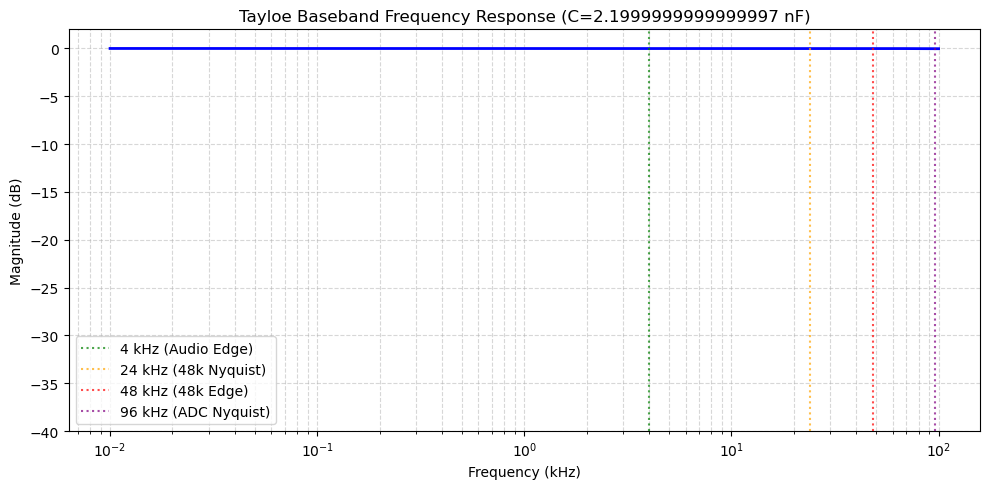

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. System Parameters
# ============================================================
f_LO = 14.0e6          # Operating frequency (20m band)
R_source = 50.0        # BPF output impedance (Ohms)
R_switch = 5.0         # 74CBTLV3253 on-resistance (Ohms)
C_tayloe = 2.2e-9       # Sampling capacitor (2.2 nF)

print(f"Tayloe Detector Analysis at f_LO = {f_LO/1e6} MHz")
print(f"Source Impedance = {R_source} Ohm")
print(f"Switch Ron = {R_switch} Ohm")
print(f"Sampling Capacitor = {C_tayloe*1e9} nF\n")

# ============================================================
# 2. Input Impedance and Matching
# ============================================================
# The Tayloe mixer acts as a switched-capacitor resistor.
# For a 4-phase clock, the equivalent input resistance is:
# R_in = 1 / (4 * f_LO * C)
R_in = 1.0 / (4.0 * f_LO * C_tayloe)

# The actual impedance seen by the BPF is R_in in parallel with the switch resistance.
# But for matching loss, we treat it as a voltage divider between R_source and R_in.
# Note: The switch resistance is part of the charging time constant, not the input match.
mismatch_loss = 20 * np.log10(R_in / (R_source + R_in))

print("--- Input Matching ---")
print(f"Equivalent Input Resistance (R_in): {R_in:.2f} Ohm")
print(f"Mismatch Loss (vs 50 Ohm): {mismatch_loss:.1f} dB")
print(f"NOTE: A lower C_tayloe would increase R_in and reduce mismatch loss.")
print(f"NOTE: A higher C_tayloe gives better audio filtering but worse match.\n")

# ============================================================
# 3. Baseband Low-Pass Filter (The RC Time Constant)
# ============================================================
# The audio bandwidth is set by the RC time constant of the source + switch
# charging the capacitor.
R_eq = R_source + R_switch
tau = R_eq * C_tayloe
f_cutoff = 1.0 / (2.0 * np.pi * tau)

print("--- Baseband Audio Filter ---")
print(f"Total Series Resistance (R_s + R_on): {R_eq:.1f} Ohm")
print(f"RC Time Constant: {tau*1e6:.2f} us")
print(f"-3 dB Baseband Cutoff: {f_cutoff/1e3:.1f} kHz\n")

# ============================================================
# 4. Frequency Response Plot (Audio Band)
# ============================================================
# Sweep from 1 Hz to 100 kHz
f_hz = np.logspace(1, 5, 1000)
w = 2 * np.pi * f_hz

# The baseband transfer function is a simple 1st-order RC low-pass
H_audio = 1.0 / (1.0 + 1j * w * tau)
mag_dB = 20 * np.log10(np.abs(H_audio))

# Plot
fig, ax = plt.subplots(figsize=(10, 5))
ax.semilogx(f_hz/1e3, mag_dB, 'b-', linewidth=2)
ax.set_title(f'Tayloe Baseband Frequency Response (C={C_tayloe*1e9} nF)')
ax.set_xlabel('Frequency (kHz)')
ax.set_ylabel('Magnitude (dB)')
ax.grid(True, which="both", ls="--", alpha=0.5)
ax.set_ylim(-40, 2)

# Mark critical frequencies
for f_mark, label, color in [
    (4, '4 kHz (Audio Edge)', 'green'),
    (24, '24 kHz (48k Nyquist)', 'orange'),
    (48, '48 kHz (48k Edge)', 'red'),
    (96, '96 kHz (ADC Nyquist)', 'purple')
]:
    ax.axvline(x=f_mark, color=color, linestyle=':', alpha=0.7, label=label)
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()